# C02c — ALISON surface-feature humanization test

This notebook tests whether ALISON humanizes the feature family it is designed to alter: normalized character and POS \(n\)-gram frequencies. It separately characterizes dose response at

\[
L\in\{0,10,15,18,20,25\}.
\]

The primary comparison is always transformed ChatGPT against **untouched human text**:

\[
\phi_{\mathrm{AL}}(AL_L(A))\quad\text{versus}\quad\phi_{\mathrm{AL}}(H).
\]

## Separation discipline

- **100 matched attack pairs** are selected deterministically as the calibration set.
- The remaining **400 matched attack pairs remain untouched** for a later confirmatory evaluation after the operating point is frozen.
- Primary evidence comes only from ALISON's 884 character and 811 POS features: direct distribution distances, coordinate-wise movement, and surface-only probes.
- The historical OpenAI detectors are external-transfer diagnostics only. They neither define surface humanization nor choose the final operating point.
- Transformed-human outputs are retained solely as an intervention-artifact control and are excluded from the primary feature-family test.

## Nested generation

All nonzero variants for a text are produced in one pass. After ALISON finishes patterns 10, 15, 18, 20, and 25, the corresponding text state is checkpointed. This is equivalent to generating each \(T_L(x)\) independently from the original ranking, while avoiding repeated BERT work.

The case-preserved outputs are primary. Release-style lowercased outputs are retained only for compatibility.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import math
import pickle
import random
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from captum.attr import IntegratedGradients
from nltk import ngrams, pos_tag, sent_tokenize, word_tokenize
from nltk.translate.meteor_score import meteor_score
from scipy.stats import wasserstein_distance
from tqdm.auto import tqdm
from transformers import (
    AutoModelForMaskedLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
)

ROOT = Path(
    ".."
)

C02B_OUT = (
    ROOT
    / "results"
    / "causal"
    / "C02b_alison_reproduction_v2"
)

OUT = (
    ROOT
    / "results"
    / "causal"
    / "C02c_alison_dose_calibration"
)
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
N_CALIBRATION_PAIRS = 100

DOSES = [10, 15, 18, 20, 25]
MAX_DOSE = max(DOSES)

C_LENGTH = 1.35
MIN_POS_LENGTH_EXCLUSIVE = 1
IG_STEPS = 1024
IG_INTERNAL_BATCH = 256

SEMANTIC_FLOOR = 0.90
LEXICAL_CHANGE_CEILING = 0.25

N_BOOT = 10_000
CI_LEVEL = 0.95

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("C02b cache:", C02B_OUT)
print("calibration output:", OUT)
print("device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C02b cache: ../results/causal/C02b_alison_reproduction_v2
calibration output: ../results/causal/C02c_alison_dose_calibration
device: cuda
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU


## 1. Load and verify the frozen C02b state

No C02b model, feature, split, or output is retrained here. The calibration notebook consumes its frozen artifacts.

In [2]:
required = {
    "split": C02B_OUT / "binary_split.parquet",
    "features": C02B_OUT / "features.pkl",
    "feature_matrix": C02B_OUT / "feature_matrix.npy",
    "feature_rows": C02B_OUT / "feature_matrix_rows.parquet",
    "scaler": C02B_OUT / "scaler.pkl",
    "model": C02B_OUT / "internal_mlp_historical.pt",
    "c02b_rankings": C02B_OUT / "ig_ranked_pos.parquet",
    "c02b_outputs": C02B_OUT / "alison_outputs.parquet",
    "detector_baseline": C02B_OUT / "external_detector_baseline.parquet",
}

for name, path in required.items():
    assert path.exists(), f"Missing C02b artifact: {name}: {path}"

data = pd.read_parquet(required["split"])
feature_rows = pd.read_parquet(required["feature_rows"])
X_all = np.load(required["feature_matrix"])

assert len(data) == len(feature_rows) == len(X_all)
assert (
    data["source_id"].astype(str).tolist()
    == feature_rows["source_id"].astype(str).tolist()
), "Feature matrix row order does not match binary_split.parquet"

with open(required["features"], "rb") as f:
    feature_bundle = pickle.load(f)

char_features = feature_bundle["char"]
pos_features = feature_bundle["pos"]

n_char = sum(len(group) for group in char_features)
n_pos = sum(len(group) for group in pos_features)
n_total = n_char + n_pos

assert X_all.shape == (len(data), n_total)

with open(required["scaler"], "rb") as f:
    scaler = pickle.load(f)

X_scaled = scaler.transform(X_all).astype(np.float32)


class HistoricalAlisonMLP(nn.Module):
    def __init__(self, in_size, num_classes):
        super().__init__()

        width = 512
        dp = 0.40

        layers = [
            nn.Dropout(dp),
            nn.Linear(in_size, width),
            nn.ReLU(),
        ]

        for _ in range(7):
            layers += [
                nn.Dropout(dp),
                nn.Linear(width, width),
                nn.ReLU(),
            ]

        layers += [
            nn.Dropout(dp),
            nn.Linear(width, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        ]

        self.stack = nn.Sequential(*layers)

    def forward(self, x):
        return self.stack(x)


internal_model = HistoricalAlisonMLP(n_total, 2)
internal_model.load_state_dict(
    torch.load(
        required["model"],
        map_location="cpu",
        weights_only=True,
    )
)
internal_model = internal_model.to(DEVICE).eval()

source_to_row = {
    str(source_id): i
    for i, source_id in enumerate(data["source_id"])
}

print("rows:", len(data))
print("feature dimension:", n_total)
print("PASS: frozen C02b state loaded")


rows: 2000
feature dimension: 1695
PASS: frozen C02b state loaded


## 2. Freeze 100 calibration pairs and 400 untouched evaluation pairs

The split is deterministic and depends only on `pair_id`, never on text, classifier scores, or transformation outcomes.

In [3]:
attack = data[
    data["split"].eq("attack_test")
].copy()

pair_table = pd.DataFrame({
    "pair_id": sorted(attack["pair_id"].unique())
})

pair_table["calibration_key"] = [
    hashlib.sha256(
        f"{SEED}|ALISON-dose-calibration|{pair_id}".encode("utf-8")
    ).hexdigest()
    for pair_id in pair_table["pair_id"]
]

pair_table = pair_table.sort_values(
    "calibration_key"
).reset_index(drop=True)

calibration_pair_ids = set(
    pair_table
    .head(N_CALIBRATION_PAIRS)["pair_id"]
    .astype(int)
)

evaluation_pair_ids = set(
    pair_table
    .iloc[N_CALIBRATION_PAIRS:]["pair_id"]
    .astype(int)
)

assert calibration_pair_ids.isdisjoint(evaluation_pair_ids)
assert len(calibration_pair_ids) == N_CALIBRATION_PAIRS
assert len(calibration_pair_ids | evaluation_pair_ids) == 500

calibration = (
    attack[
        attack["pair_id"].isin(calibration_pair_ids)
    ]
    .sort_values(["pair_id", "label"])
    .reset_index(drop=True)
)

evaluation_holdout = (
    attack[
        attack["pair_id"].isin(evaluation_pair_ids)
    ]
    .sort_values(["pair_id", "label"])
    .reset_index(drop=True)
)

assert len(calibration) == 2 * N_CALIBRATION_PAIRS
assert calibration.groupby("pair_id").size().eq(2).all()
assert calibration.groupby("pair_id").label.nunique().eq(2).all()
assert len(evaluation_holdout) == 800

split_manifest = {
    "seed": SEED,
    "selection_key": "SHA256(seed|ALISON-dose-calibration|pair_id)",
    "n_calibration_pairs": len(calibration_pair_ids),
    "n_evaluation_pairs": len(evaluation_pair_ids),
    "calibration_pair_ids": sorted(calibration_pair_ids),
    "evaluation_pair_ids": sorted(evaluation_pair_ids),
}

with open(OUT / "calibration_split.json", "w") as f:
    json.dump(split_manifest, f, indent=2)

display(
    calibration.groupby("class_name")
    .size()
    .rename("n_calibration")
    .to_frame()
)

print("untouched evaluation pairs:", len(evaluation_pair_ids))
print("saved:", OUT / "calibration_split.json")


,n_calibration
class_name,
chatgpt,100
human,100


untouched evaluation pairs: 400
saved: ../results/causal/C02c_alison_dose_calibration/calibration_split.json


## 3. Extend Integrated Gradients rankings to the top 25 patterns

C02b saved only the top 15 patterns. This cell recomputes rankings for the 200 calibration texts and checkpoints the top 25. The frozen internal model and frozen feature representation are unchanged.

In [4]:
flat_pos = [
    feat
    for group in pos_features
    for feat in group
]

assert len(flat_pos) == n_pos

RANK25_PATH = OUT / "ig_ranked_pos_top25.parquet"

if RANK25_PATH.exists():
    ranks25 = pd.read_parquet(RANK25_PATH)
else:
    ranks25 = pd.DataFrame(columns=[
        "source_id",
        "pair_id",
        "label",
        "class_name",
        "patterns_json",
        "scores_json",
        "seconds",
    ])

done_rank = set(
    ranks25["source_id"].astype(str)
) if len(ranks25) else set()

ig = IntegratedGradients(internal_model)

rank_jobs = [
    r
    for r in calibration.itertuples(index=False)
    if str(r.source_id) not in done_rank
]

for r in tqdm(
    rank_jobs,
    desc="Calibration IG top-25",
    unit="text",
):
    i = source_to_row[str(r.source_id)]

    x = torch.tensor(
        X_scaled[i:i+1],
        dtype=torch.float32,
        device=DEVICE,
    )

    t0 = time.time()

    attr = (
        ig.attribute(
            x,
            target=int(r.label),
            n_steps=IG_STEPS,
            internal_batch_size=IG_INTERNAL_BATCH,
        )[0]
        .detach()
        .cpu()
        .numpy()
    )

    pos_attr = attr[n_char:n_char+n_pos]

    weighted = np.asarray([
        pos_attr[j] * (C_LENGTH ** len(flat_pos[j]))
        for j in range(n_pos)
    ])

    order = np.argsort(weighted)[::-1]

    selected = [
        j
        for j in order
        if len(flat_pos[j]) > MIN_POS_LENGTH_EXCLUSIVE
    ][:MAX_DOSE]

    assert len(selected) == MAX_DOSE

    row = pd.DataFrame([{
        "source_id": str(r.source_id),
        "pair_id": int(r.pair_id),
        "label": int(r.label),
        "class_name": str(r.class_name),
        "patterns_json": json.dumps([
            "".join(flat_pos[j])
            for j in selected
        ]),
        "scores_json": json.dumps([
            float(weighted[j])
            for j in selected
        ]),
        "seconds": float(time.time() - t0),
    }])

    ranks25 = pd.concat(
        [ranks25, row],
        ignore_index=True,
    )

    ranks25.to_parquet(
        RANK25_PATH,
        index=False,
    )

    done_rank.add(str(r.source_id))

assert len(ranks25) == len(calibration)
assert not ranks25["source_id"].duplicated().any()

print("ranked:", len(ranks25), "/", len(calibration))
print("mean IG seconds/text:", ranks25["seconds"].astype(float).mean())
print("saved:", RANK25_PATH)


Calibration IG top-25: 0text [00:00, ?text/s]

ranked: 200 / 200
mean IG seconds/text: 0.4030580174922943
saved: ../results/causal/C02c_alison_dose_calibration/ig_ranked_pos_top25.parquet


## 4. Generate nested ALISON dose variants

Each text is ranked once and edited through the top 25 patterns once. Snapshots are saved after doses 10, 15, 18, 20, and 25. Every completed text-dose row is checkpointed.

In [5]:
# The internal model is not needed while BERT performs replacement.
internal_model = internal_model.cpu()
del ig
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

PENN_TAGS = [
    "CC", "CD", "DT", "EX", "FW", "IN", "JJ", "JJR", "JJS", "LS",
    "MD", "NN", "NNS", "NNP", "NNPS", "PDT", "POS", "PRP", "PRP$",
    "RB", "RBR", "RBS", "RP", "SYM", "TO", "UH", "VB", "VBD",
    "VBG", "VBN", "VBP", "VBZ", "WDT", "WP", "WP$", "WRB",
]

tag_map = {}
idx = 0
offset = 65

for tag_name in PENN_TAGS:
    if offset + idx == 90:
        offset = 72

    tag_map[tag_name] = chr(offset + idx)
    idx += 1


def tokenize_words(text):
    words = []

    for sentence in sent_tokenize(text):
        words.extend(word_tokenize(sentence))

    return words


def compressed_tags_for_words(words):
    return [
        tag_map.get(tag, tag)
        for _, tag in pos_tag(words)
    ]


def compressed_pos(text):
    return "".join(
        compressed_tags_for_words(
            tokenize_words(text)
        )
    )


def clean_spacing(text, lowercase=False):
    text = text.strip().strip('"').strip("'")
    text = re.sub(r"\s+", " ", text)

    for punct in ["!", ".", "?", ":", ";", ","]:
        text = text.replace(f" {punct}", punct)

    text = text.replace("' ", "'")
    text = text.replace("#", "")
    text = text.replace("( ", "(").replace(" )", ")")

    return text.lower() if lowercase else text


MLM_ID = "bert-large-uncased"

mlm_tok = AutoTokenizer.from_pretrained(MLM_ID)
mlm = AutoModelForMaskedLM.from_pretrained(
    MLM_ID
).to(DEVICE).eval()

MASK = mlm_tok.mask_token


def local_window(words, lo, hi, max_tokens=500):
    left = max(0, lo - 180)
    right = min(len(words), hi + 180)

    while True:
        test_words = list(words[left:right])
        local_lo = lo - left
        local_hi = hi - left

        test_words[local_lo:local_hi] = [
            MASK
        ] * (hi - lo)

        n_tokens = len(
            mlm_tok(
                " ".join(test_words),
                add_special_tokens=True,
                verbose=False,
            )["input_ids"]
        )

        if n_tokens <= max_tokens:
            return left, right

        left_spare = lo - left
        right_spare = right - hi

        if left_spare >= right_spare and left < lo:
            left += max(1, min(20, left_spare))
        elif right > hi:
            right -= max(1, min(20, right_spare))
        else:
            raise RuntimeError(
                "Masked span itself exceeds BERT's context window."
            )


@torch.inference_mode()
def replace_interval(words, lo, hi):
    original_span = list(words[lo:hi])
    left, right = local_window(words, lo, hi)

    local = list(words[left:right])
    local_lo = lo - left
    local_hi = hi - left

    local[local_lo:local_hi] = [MASK] * (hi - lo)

    enc = mlm_tok(
        " ".join(local),
        return_tensors="pt",
        truncation=True,
        max_length=512,
    ).to(DEVICE)

    mask_positions = (
        enc["input_ids"][0]
        .eq(mlm_tok.mask_token_id)
        .nonzero(as_tuple=False)
        .flatten()
    )

    if len(mask_positions) != hi - lo:
        return words, 0, 0, False

    logits = mlm(**enc).logits[0]
    pred_ids = logits[mask_positions].argmax(-1).tolist()
    pred_tokens = mlm_tok.convert_ids_to_tokens(pred_ids)

    replacements = []

    for original_word, prediction in zip(
        original_span,
        pred_tokens,
    ):
        prediction = prediction.replace("##", "")
        prediction = re.sub(
            r"[^\w\s'-]",
            "",
            prediction,
        ).strip()

        replacements.append(
            prediction if prediction else original_word
        )

    lexical_changes = sum(
        str(old).casefold() != str(new).casefold()
        for old, new in zip(
            original_span,
            replacements,
        )
    )

    new_words = list(words)
    new_words[lo:hi] = replacements

    return (
        new_words,
        len(replacements),
        lexical_changes,
        True,
    )


rank_map25 = {
    str(r.source_id): json.loads(r.patterns_json)
    for r in ranks25.itertuples(index=False)
}

DOSE_PATH = OUT / "alison_dose_variants.parquet"

if DOSE_PATH.exists():
    dose_variants = pd.read_parquet(DOSE_PATH)
else:
    dose_variants = pd.DataFrame()

existing_keys = set()

if len(dose_variants):
    existing_keys = set(zip(
        dose_variants["source_id"].astype(str),
        dose_variants["dose"].astype(int),
    ))

generation_jobs = [
    r
    for r in calibration.itertuples(index=False)
    if any(
        (str(r.source_id), dose) not in existing_keys
        for dose in DOSES
    )
]

for r in tqdm(
    generation_jobs,
    desc="Nested ALISON doses",
    unit="text",
):
    t0 = time.time()

    original_words = tokenize_words(r.text)
    words = list(original_words)
    tags = compressed_tags_for_words(original_words)
    changed = [False] * len(words)

    cumulative_candidate_intervals = 0
    cumulative_changed_intervals = 0
    cumulative_replaced_tokens = 0
    cumulative_lexical_changes = 0
    cumulative_failures = 0

    patterns = rank_map25[str(r.source_id)]
    assert len(patterns) >= MAX_DOSE

    new_rows = []

    for pattern_rank, pattern in enumerate(
        patterns[:MAX_DOSE],
        start=1,
    ):
        pat = list(pattern)
        n = len(pat)

        intervals = [
            (start, start + n)
            for start in range(
                0,
                max(0, len(tags) - n + 1),
            )
            if tags[start:start+n] == pat
        ]

        cumulative_candidate_intervals += len(intervals)

        for lo, hi in intervals:
            if hi > len(changed):
                continue

            if any(changed[lo:hi]):
                continue

            (
                new_words,
                n_replaced,
                n_lexically_changed,
                success,
            ) = replace_interval(words, lo, hi)

            if success:
                words = new_words
                changed[lo:hi] = [True] * (hi - lo)

                cumulative_changed_intervals += 1
                cumulative_replaced_tokens += n_replaced
                cumulative_lexical_changes += n_lexically_changed
            else:
                cumulative_failures += 1

        if pattern_rank in DOSES:
            case_preserved = clean_spacing(
                " ".join(words),
                lowercase=False,
            )

            release_text = clean_spacing(
                " ".join(words),
                lowercase=True,
            )

            new_rows.append({
                "source_id": str(r.source_id),
                "pair_id": int(r.pair_id),
                "label": int(r.label),
                "class_name": str(r.class_name),
                "dose": int(pattern_rank),
                "original": str(r.text),
                "obfuscated_case_preserved": case_preserved,
                "obfuscated_release": release_text,
                "n_candidate_intervals": int(
                    cumulative_candidate_intervals
                ),
                "n_changed_intervals": int(
                    cumulative_changed_intervals
                ),
                "n_replaced_tokens": int(
                    cumulative_replaced_tokens
                ),
                "n_lexically_changed_tokens": int(
                    cumulative_lexical_changes
                ),
                "masked_word_fraction": float(
                    sum(changed) / max(1, len(changed))
                ),
                "lexical_change_fraction": float(
                    cumulative_lexical_changes
                    / max(1, len(changed))
                ),
                "replacement_failures": int(
                    cumulative_failures
                ),
                "seconds_cumulative": float(
                    time.time() - t0
                ),
            })

    rows_to_add = [
        row
        for row in new_rows
        if (
            row["source_id"],
            row["dose"],
        ) not in existing_keys
    ]

    if rows_to_add:
        dose_variants = pd.concat(
            [
                dose_variants,
                pd.DataFrame(rows_to_add),
            ],
            ignore_index=True,
        )

        dose_variants.to_parquet(
            DOSE_PATH,
            index=False,
        )

        for row in rows_to_add:
            existing_keys.add((
                row["source_id"],
                row["dose"],
            ))

expected_rows = len(calibration) * len(DOSES)

assert len(dose_variants) == expected_rows
assert not dose_variants.duplicated(
    ["source_id", "dose"]
).any()
assert dose_variants["replacement_failures"].astype(int).eq(0).all()

print("saved variants:", len(dose_variants), "/", expected_rows)
print("saved:", DOSE_PATH)


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████| 394/394 [00:00<00:00, 11885.30it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-large-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Nested ALISON doses: 0text [00:00, ?text/s]

saved variants: 1000 / 1000
saved: ../results/causal/C02c_alison_dose_calibration/alison_dose_variants.parquet


## 5. Verify that the nested \(L=15\) snapshot reproduces C02b

This is an implementation invariant. The newly generated dose-15 text should match the frozen C02b dose-15 text for the same calibration samples.

In [6]:
c02b_obf = pd.read_parquet(
    required["c02b_outputs"]
)[
    [
        "source_id",
        "obfuscated_release",
        "obfuscated_case_preserved",
    ]
].rename(columns={
    "obfuscated_release": "c02b_release",
    "obfuscated_case_preserved": "c02b_case_preserved",
})

parity = (
    dose_variants[
        dose_variants["dose"].astype(int).eq(15)
    ][
        [
            "source_id",
            "obfuscated_release",
            "obfuscated_case_preserved",
        ]
    ]
    .merge(
        c02b_obf,
        on="source_id",
        how="inner",
        validate="one_to_one",
    )
)

parity["release_exact"] = (
    parity["obfuscated_release"]
    == parity["c02b_release"]
)

parity["case_exact"] = (
    parity["obfuscated_case_preserved"]
    == parity["c02b_case_preserved"]
)

parity_summary = pd.DataFrame([{
    "n": len(parity),
    "release_exact_rate": parity["release_exact"].mean(),
    "case_preserved_exact_rate": parity["case_exact"].mean(),
}])

display(parity_summary)

assert len(parity) == len(calibration)
assert parity["release_exact"].mean() >= 0.95
assert parity["case_exact"].mean() >= 0.95

parity_summary.to_csv(
    OUT / "dose15_parity_check.csv",
    index=False,
)

print("PASS: nested generator reproduces frozen C02b at L=15")


,n,release_exact_rate,case_preserved_exact_rate
0,200,1.0,1.0


PASS: nested generator reproduces frozen C02b at L=15


## 6. Score the complete dose curve with ALISON's internal classifier

The primary calibration score is the probability of the ChatGPT class under ALISON's frozen internal classifier. Case-preserved variants are used.

In [7]:
def release_block(sequence, feature_groups):
    values = []

    for group in feature_groups:
        n = len(group[0])
        denominator = len(Counter(ngrams(sequence, n)))

        for feature in group:
            values.append(
                sequence.count("".join(feature)) / denominator
                if denominator != 0
                else 0.0
            )

    return values


def alison_rep(text):
    pos_text = compressed_pos(text)

    return np.asarray(
        release_block(text, char_features)
        + release_block(pos_text, pos_features),
        dtype=np.float32,
    )


INTERNAL_SCORE_PATH = OUT / "internal_dose_scores.parquet"

if INTERNAL_SCORE_PATH.exists():
    internal_scores = pd.read_parquet(INTERNAL_SCORE_PATH)

else:
    variant_features = np.stack([
        alison_rep(text)
        for text in tqdm(
            dose_variants["obfuscated_case_preserved"],
            desc="Dose feature vectors",
            unit="text",
        )
    ])

    variant_scaled = scaler.transform(
        variant_features
    ).astype(np.float32)

    internal_model = internal_model.to(DEVICE).eval()

    probabilities = []

    with torch.inference_mode():
        for start in range(0, len(variant_scaled), 512):
            xb = torch.tensor(
                variant_scaled[start:start+512],
                dtype=torch.float32,
                device=DEVICE,
            )

            p = (
                internal_model(xb)
                .softmax(-1)[:, 1]
                .cpu()
                .numpy()
            )

            probabilities.extend(p.tolist())

    internal_scores = dose_variants[
        [
            "source_id",
            "pair_id",
            "label",
            "class_name",
            "dose",
            "lexical_change_fraction",
        ]
    ].copy()

    internal_scores["internal_machine_prob"] = probabilities

    original_rows = []

    calibration_source_ids = set(
        calibration["source_id"].astype(str)
    )

    original_positions = [
        source_to_row[source_id]
        for source_id in calibration["source_id"].astype(str)
    ]

    with torch.inference_mode():
        original_probabilities = (
            internal_model(
                torch.tensor(
                    X_scaled[original_positions],
                    dtype=torch.float32,
                    device=DEVICE,
                )
            )
            .softmax(-1)[:, 1]
            .cpu()
            .numpy()
        )

    for r, probability in zip(
        calibration.itertuples(index=False),
        original_probabilities,
    ):
        assert str(r.source_id) in calibration_source_ids

        original_rows.append({
            "source_id": str(r.source_id),
            "pair_id": int(r.pair_id),
            "label": int(r.label),
            "class_name": str(r.class_name),
            "dose": 0,
            "lexical_change_fraction": 0.0,
            "internal_machine_prob": float(probability),
        })

    internal_scores = pd.concat(
        [
            pd.DataFrame(original_rows),
            internal_scores,
        ],
        ignore_index=True,
    )

    internal_scores.to_parquet(
        INTERNAL_SCORE_PATH,
        index=False,
    )

expected_internal_rows = len(calibration) * (len(DOSES) + 1)

assert len(internal_scores) == expected_internal_rows
assert not internal_scores.duplicated(
    ["source_id", "dose"]
).any()

print("saved:", INTERNAL_SCORE_PATH)


saved: ../results/causal/C02c_alison_dose_calibration/internal_dose_scores.parquet


## 7. Semantic preservation for each dose

BERTScore is computed on the case-preserved variants. The result is cached and becomes part of the dose-selection constraint.

In [8]:
# Free models before BERTScore loads RoBERTa-large.
if "mlm" in globals():
    del mlm

if "internal_model" in globals():
    internal_model = internal_model.cpu()

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

SEM_PATH = OUT / "dose_semantic_metrics.parquet"

if SEM_PATH.exists():
    dose_semantic = pd.read_parquet(SEM_PATH)

else:
    from bert_score import score as bertscore

    dose_semantic = dose_variants[
        [
            "source_id",
            "pair_id",
            "label",
            "class_name",
            "dose",
            "original",
            "obfuscated_case_preserved",
            "lexical_change_fraction",
        ]
    ].copy()

    dose_semantic["meteor"] = [
        meteor_score(
            [word_tokenize(original)],
            word_tokenize(transformed),
        )
        for original, transformed in tqdm(
            zip(
                dose_semantic["original"],
                dose_semantic["obfuscated_case_preserved"],
            ),
            total=len(dose_semantic),
            desc="Dose METEOR",
            unit="text",
        )
    ]

    _, _, bert_f1 = bertscore(
        dose_semantic["obfuscated_case_preserved"].tolist(),
        dose_semantic["original"].tolist(),
        lang="en",
        verbose=True,
        device=DEVICE,
        batch_size=16,
    )

    dose_semantic["bertscore_f1"] = bert_f1.cpu().numpy()

    dose_semantic.to_parquet(
        SEM_PATH,
        index=False,
    )

assert len(dose_semantic) == len(dose_variants)
assert not dose_semantic.duplicated(
    ["source_id", "dose"]
).any()

print("saved:", SEM_PATH)


saved: ../results/causal/C02c_alison_dose_calibration/dose_semantic_metrics.parquet


## 8. Select a global dose without target-detector feedback

For each dose, compare transformed ChatGPT internal-score distribution with the original human calibration distribution using one-dimensional Wasserstein distance.

A dose is eligible only if its transformed ChatGPT texts satisfy:

\[
\overline{\mathrm{BERTScore}}\ge 0.90,
\qquad
\overline{ho}_{\mathrm{lexical}}\le 0.25.
\]

Among eligible doses, choose the one with minimum Wasserstein distance. External detector outputs are not loaded until after this choice is written to disk.

In [9]:
alpha = (1.0 - CI_LEVEL) / 2.0


def bootstrap_mean_ci(values, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    indices = rng.integers(
        0,
        len(values),
        size=(N_BOOT, len(values)),
    )

    boot = values[indices].mean(axis=1)
    lo, hi = np.quantile(
        boot,
        [alpha, 1.0 - alpha],
    )

    return float(values.mean()), float(lo), float(hi)


human_reference = internal_scores[
    internal_scores["class_name"].eq("human")
    & internal_scores["dose"].astype(int).eq(0)
]["internal_machine_prob"].astype(float).to_numpy()

human_mean = float(human_reference.mean())
human_median = float(np.median(human_reference))
human_q10, human_q90 = np.quantile(
    human_reference,
    [0.10, 0.90],
)

selection_table_rows = []

for dose in [0] + DOSES:
    ai = internal_scores[
        internal_scores["class_name"].eq("chatgpt")
        & internal_scores["dose"].astype(int).eq(dose)
    ]

    mean_prob, ci_low, ci_high = bootstrap_mean_ci(
        ai["internal_machine_prob"],
        seed=SEED + dose,
    )

    if dose == 0:
        mean_bertscore = 1.0
        mean_meteor = 1.0
        mean_lexical_change = 0.0
    else:
        sem = dose_semantic[
            dose_semantic["class_name"].eq("chatgpt")
            & dose_semantic["dose"].astype(int).eq(dose)
        ]

        mean_bertscore = float(sem["bertscore_f1"].mean())
        mean_meteor = float(sem["meteor"].mean())
        mean_lexical_change = float(
            sem["lexical_change_fraction"].mean()
        )

    distance = float(wasserstein_distance(
        human_reference,
        ai["internal_machine_prob"].astype(float),
    ))

    eligible = bool(
        dose > 0
        and mean_bertscore >= SEMANTIC_FLOOR
        and mean_lexical_change <= LEXICAL_CHANGE_CEILING
    )

    selection_table_rows.append({
        "dose": int(dose),
        "n_chatgpt": len(ai),
        "mean_internal_machine_prob": mean_prob,
        "mean_ci_low": ci_low,
        "mean_ci_high": ci_high,
        "human_reference_mean": human_mean,
        "human_reference_median": human_median,
        "human_reference_q10": float(human_q10),
        "human_reference_q90": float(human_q90),
        "wasserstein_to_original_human": distance,
        "mean_bertscore": mean_bertscore,
        "mean_meteor": mean_meteor,
        "mean_lexical_change_fraction": mean_lexical_change,
        "eligible": eligible,
    })

selection_table = pd.DataFrame(selection_table_rows)

eligible_table = selection_table[
    selection_table["eligible"]
].copy()

if len(eligible_table):
    selected_global_dose = int(
        eligible_table.sort_values([
            "wasserstein_to_original_human",
            "dose",
        ]).iloc[0]["dose"]
    )
    selection_status = "eligible optimum"
else:
    selected_global_dose = int(
        selection_table[
            selection_table["dose"].gt(0)
        ]
        .sort_values([
            "wasserstein_to_original_human",
            "dose",
        ])
        .iloc[0]["dose"]
    )
    selection_status = "fallback: no dose met semantic/edit constraints"

selection_table["selected"] = (
    selection_table["dose"].eq(selected_global_dose)
)

display(selection_table.round(4))

selection_table.to_csv(
    OUT / "internal_dose_selection_table.csv",
    index=False,
)

selection_record = {
    "selected_global_dose": selected_global_dose,
    "selection_status": selection_status,
    "selection_metric": (
        "minimum Wasserstein distance between transformed ChatGPT and "
        "original human internal-machine-probability distributions"
    ),
    "semantic_floor_mean_bertscore": SEMANTIC_FLOOR,
    "lexical_change_ceiling_mean": LEXICAL_CHANGE_CEILING,
    "external_detectors_used_for_selection": False,
    "case_preserved_outputs_used": True,
    "calibration_pairs": N_CALIBRATION_PAIRS,
    "untouched_evaluation_pairs": len(evaluation_pair_ids),
}

with open(OUT / "selected_dose.json", "w") as f:
    json.dump(selection_record, f, indent=2)

print("selected global dose:", selected_global_dose)
print("status:", selection_status)
print("saved:", OUT / "selected_dose.json")


,dose,n_chatgpt,mean_internal_machine_prob,mean_ci_low,mean_ci_high,human_reference_mean,human_reference_median,human_reference_q10,human_reference_q90,wasserstein_to_original_human,mean_bertscore,mean_meteor,mean_lexical_change_fraction,eligible,selected
0,0,100,0.5243,0.5074,0.5365,0.0335,0.0001,0.0,0.0229,0.4908,1.0000,1.0000,0.0000,False,False
1,10,100,0.4785,0.4479,0.5050,0.0335,0.0001,0.0,0.0229,0.4450,0.9530,0.8677,0.1225,True,False
2,15,100,0.4789,0.4489,0.5048,0.0335,0.0001,0.0,0.0229,0.4453,0.9440,0.8261,0.1574,True,False
3,18,100,0.4648,0.4330,0.4941,0.0335,0.0001,0.0,0.0229,0.4313,0.9401,0.8079,0.1740,True,False
4,20,100,0.4647,0.4311,0.4933,0.0335,0.0001,0.0,0.0229,0.4312,0.9380,0.7984,0.1829,True,False
5,25,100,0.4536,0.4178,0.4855,0.0335,0.0001,0.0,0.0229,0.4201,0.9327,0.7747,0.2042,True,True


selected global dose: 25
status: eligible optimum
saved: ../results/causal/C02c_alison_dose_calibration/selected_dose.json


## 9. Characterize an adaptive per-text stopping rule

This analysis does not override the globally selected dose. It asks how often each transformed ChatGPT text enters the central 80% human internal-score band.

For each ChatGPT text, select the smallest eligible dose inside the human band. If none enters, retain the eligible dose closest to the human median. The resulting distribution is diagnostic and may motivate a later adaptive intervention.

In [10]:
adaptive_rows = []

semantic_lookup = dose_semantic[
    dose_semantic["class_name"].eq("chatgpt")
][
    [
        "source_id",
        "dose",
        "bertscore_f1",
        "lexical_change_fraction",
    ]
]

ai_candidates = (
    internal_scores[
        internal_scores["class_name"].eq("chatgpt")
        & internal_scores["dose"].astype(int).gt(0)
    ]
    .merge(
        semantic_lookup,
        on=["source_id", "dose"],
        how="inner",
        validate="one_to_one",
        suffixes=("", "_semantic"),
    )
)

for source_id, candidates in ai_candidates.groupby("source_id"):
    candidates = candidates.copy()

    candidates["semantically_eligible"] = (
        candidates["bertscore_f1"].astype(float).ge(SEMANTIC_FLOOR)
        & candidates["lexical_change_fraction_semantic"].astype(float)
        .le(LEXICAL_CHANGE_CEILING)
    )

    candidates["inside_human_band"] = (
        candidates["internal_machine_prob"].astype(float).ge(human_q10)
        & candidates["internal_machine_prob"].astype(float).le(human_q90)
    )

    inside = candidates[
        candidates["semantically_eligible"]
        & candidates["inside_human_band"]
    ].sort_values("dose")

    if len(inside):
        chosen = inside.iloc[0]
        reason = "smallest eligible dose inside human q10-q90"
        reached_band = True
    else:
        eligible = candidates[
            candidates["semantically_eligible"]
        ].copy()

        if not len(eligible):
            eligible = candidates.copy()
            reason = "fallback: no candidate met semantic/edit limits"
        else:
            reason = "closest eligible dose to human median"

        eligible["distance_to_human_median"] = (
            eligible["internal_machine_prob"].astype(float)
            - human_median
        ).abs()

        chosen = eligible.sort_values([
            "distance_to_human_median",
            "dose",
        ]).iloc[0]

        reached_band = False

    adaptive_rows.append({
        "source_id": str(source_id),
        "pair_id": int(chosen["pair_id"]),
        "selected_dose": int(chosen["dose"]),
        "internal_machine_prob": float(
            chosen["internal_machine_prob"]
        ),
        "bertscore_f1": float(chosen["bertscore_f1"]),
        "lexical_change_fraction": float(
            chosen["lexical_change_fraction_semantic"]
        ),
        "reached_human_band": bool(reached_band),
        "selection_reason": reason,
    })

adaptive_selection = pd.DataFrame(adaptive_rows)

display(
    adaptive_selection.groupby([
        "selected_dose",
        "reached_human_band",
    ])
    .size()
    .rename("n")
    .to_frame()
)

print(
    "fraction entering human band:",
    adaptive_selection["reached_human_band"].mean(),
)

adaptive_selection.to_csv(
    OUT / "adaptive_dose_diagnostic.csv",
    index=False,
)

print("saved:", OUT / "adaptive_dose_diagnostic.csv")


n
selected_dose reached_human_band    
10            False                9
              True                 7
15            False               16
              True                 1
18            False               16
              True                 1
20            False               17
25            False               32
              True                 1

fraction entering human band: 0.1
saved: ../results/causal/C02c_alison_dose_calibration/adaptive_dose_diagnostic.csv


## 10. External detector dose-response audit

Only now—after `selected_dose.json` exists—are the historical OpenAI detectors loaded. These scores validate transfer and do not influence the selected dose.

In [11]:
DETECTORS = {
    "openai_base":
        "openai-community/roberta-base-openai-detector",

    "openai_large":
        "openai-community/roberta-large-openai-detector",
}

EXTERNAL_DOSE_PATH = OUT / "external_detector_dose_scores.parquet"

if EXTERNAL_DOSE_PATH.exists():
    external_dose_scores = pd.read_parquet(EXTERNAL_DOSE_PATH)

else:
    external_rows = []

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    for detector_name, checkpoint in DETECTORS.items():
        print("\n==", detector_name, "==")

        tok = AutoTokenizer.from_pretrained(checkpoint)
        clf = AutoModelForSequenceClassification.from_pretrained(
            checkpoint
        ).to(DEVICE).eval()

        id2label = {
            int(k): str(v)
            for k, v in clf.config.id2label.items()
        }

        fake_matches = [
            k
            for k, value in id2label.items()
            if "fake" in value.lower()
        ]

        if fake_matches:
            fake_id = fake_matches[0]
        else:
            assert checkpoint in set(DETECTORS.values())
            assert clf.config.num_labels == 2
            fake_id = 0

            print(
                "generic labels:",
                id2label,
                "| class 0 = Fake/generated",
            )

        texts = dose_variants[
            "obfuscated_case_preserved"
        ].tolist()

        probabilities = []

        with torch.inference_mode():
            for start in tqdm(
                range(0, len(texts), 16),
                desc=f"{detector_name} dose variants",
                unit="batch",
            ):
                enc = tok(
                    texts[start:start+16],
                    padding=True,
                    truncation=True,
                    max_length=512,
                    return_tensors="pt",
                ).to(DEVICE)

                p = (
                    clf(**enc)
                    .logits
                    .softmax(-1)[:, fake_id]
                    .cpu()
                    .numpy()
                )

                probabilities.extend(p.tolist())

        assert len(probabilities) == len(dose_variants)

        for r, probability in zip(
            dose_variants.itertuples(index=False),
            probabilities,
        ):
            external_rows.append({
                "source_id": str(r.source_id),
                "pair_id": int(r.pair_id),
                "label": int(r.label),
                "class_name": str(r.class_name),
                "dose": int(r.dose),
                "detector": detector_name,
                "fake_probability": float(probability),
                "predicted_fake": int(probability >= 0.5),
            })

        del clf, tok
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    external_dose_scores = pd.DataFrame(external_rows)

    external_dose_scores.to_parquet(
        EXTERNAL_DOSE_PATH,
        index=False,
    )

baseline_scores = pd.read_parquet(
    required["detector_baseline"]
)

calibration_ids = set(
    calibration["source_id"].astype(str)
)

baseline_calibration = baseline_scores[
    baseline_scores["source_id"].astype(str).isin(calibration_ids)
][
    [
        "source_id",
        "detector",
        "label",
        "class_name",
        "original_fake_prob",
    ]
].merge(
    calibration[["source_id", "pair_id"]],
    on="source_id",
    how="inner",
    validate="many_to_one",
)

baseline_calibration = baseline_calibration.rename(columns={
    "original_fake_prob": "fake_probability",
})

baseline_calibration["dose"] = 0
baseline_calibration["predicted_fake"] = (
    baseline_calibration["fake_probability"].astype(float).ge(0.5)
).astype(int)

external_all = pd.concat(
    [
        baseline_calibration[
            external_dose_scores.columns
        ],
        external_dose_scores,
    ],
    ignore_index=True,
)

assert not external_all.duplicated(
    ["source_id", "detector", "dose"]
).any()

summary_rows = []

for (
    detector_name,
    class_name,
    dose,
), group in external_all.groupby([
    "detector",
    "class_name",
    "dose",
]):
    mean_prob, prob_low, prob_high = bootstrap_mean_ci(
        group["fake_probability"],
        seed=(
            SEED
            + int(dose)
            + (0 if class_name == "human" else 100)
            + (0 if detector_name == "openai_base" else 1000)
        ),
    )

    mean_rate, rate_low, rate_high = bootstrap_mean_ci(
        group["predicted_fake"],
        seed=(
            SEED
            + int(dose)
            + (0 if class_name == "human" else 200)
            + (0 if detector_name == "openai_base" else 2000)
        ),
    )

    summary_rows.append({
        "detector": detector_name,
        "class_name": class_name,
        "dose": int(dose),
        "n": len(group),
        "mean_fake_probability": mean_prob,
        "fake_probability_ci_low": prob_low,
        "fake_probability_ci_high": prob_high,
        "predicted_fake_rate": mean_rate,
        "predicted_fake_rate_ci_low": rate_low,
        "predicted_fake_rate_ci_high": rate_high,
        "selected_global_dose": int(
            int(dose) == selected_global_dose
        ),
    })

external_summary = pd.DataFrame(summary_rows)

display(
    external_summary.sort_values([
        "detector",
        "class_name",
        "dose",
    ]).round(4)
)

external_summary.to_csv(
    OUT / "external_detector_dose_summary.csv",
    index=False,
)

print("saved:", EXTERNAL_DOSE_PATH)
print("saved:", OUT / "external_detector_dose_summary.csv")


,detector,class_name,dose,n,mean_fake_probability,fake_probability_ci_low,fake_probability_ci_high,predicted_fake_rate,predicted_fake_rate_ci_low,predicted_fake_rate_ci_high,selected_global_dose
0,openai_base,chatgpt,0,100,0.9479,0.9061,0.9814,0.95,0.90,0.99,0
1,openai_base,chatgpt,10,100,0.2335,0.1598,0.3162,0.22,0.14,0.30,0
2,openai_base,chatgpt,15,100,0.1858,0.1175,0.2591,0.18,0.11,0.26,0
3,openai_base,chatgpt,18,100,0.1693,0.1038,0.2408,0.16,0.09,0.23,0
4,openai_base,chatgpt,20,100,0.1623,0.0987,0.2329,0.15,0.08,0.22,0
5,openai_base,chatgpt,25,100,0.1922,0.1242,0.2664,0.19,0.12,0.27,1
6,openai_base,human,0,100,0.0042,0.0011,0.0082,0.00,0.00,0.00,0
7,openai_base,human,10,100,0.1239,0.0707,0.1844,0.14,0.08,0.21,0
8,openai_base,human,15,100,0.1321,0.0784,0.1917,0.13,0.07,0.20,0
9,openai_base,human,18,100,0.1433,0.0871,0.2041,0.15,0.08,0.22,0


saved: ../results/causal/C02c_alison_dose_calibration/external_detector_dose_scores.parquet
saved: ../results/causal/C02c_alison_dose_calibration/external_detector_dose_summary.csv


## 11. Visualize the dose response

The selected dose is shown as a vertical dotted line. These figures are diagnostic; external curves do not revise the frozen selection.

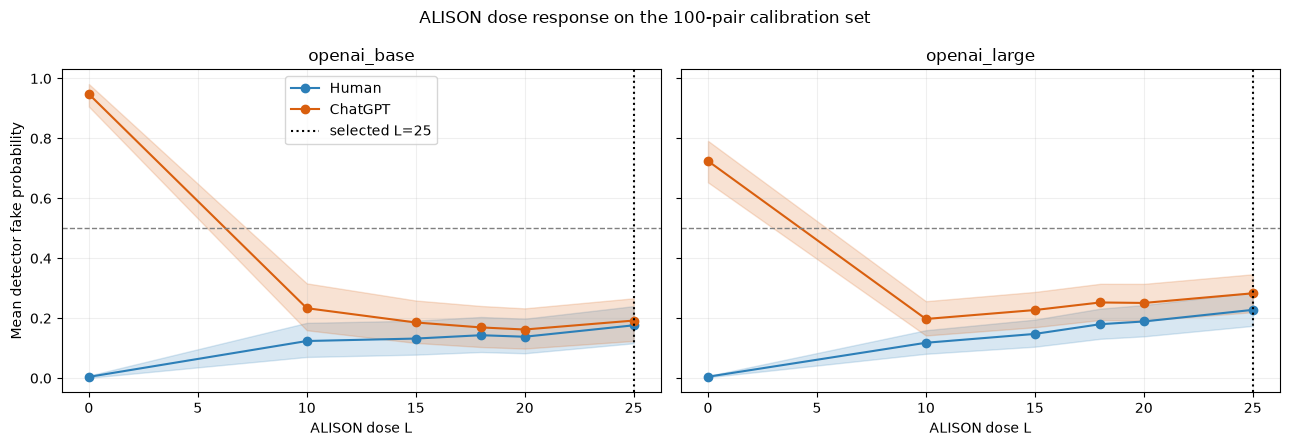

saved: ../results/causal/C02c_alison_dose_calibration/external_detector_dose_response.png


In [12]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
    sharey=True,
)

for ax, detector_name in zip(
    axes,
    ["openai_base", "openai_large"],
):
    d = external_summary[
        external_summary["detector"].eq(detector_name)
    ]

    for class_name, label, color in [
        ("human", "Human", "#2c7fb8"),
        ("chatgpt", "ChatGPT", "#d95f0e"),
    ]:
        g = d[
            d["class_name"].eq(class_name)
        ].sort_values("dose")

        ax.plot(
            g["dose"],
            g["mean_fake_probability"],
            marker="o",
            label=label,
            color=color,
        )

        ax.fill_between(
            g["dose"].to_numpy(),
            g["fake_probability_ci_low"].to_numpy(),
            g["fake_probability_ci_high"].to_numpy(),
            alpha=0.18,
            color=color,
        )

    ax.axvline(
        selected_global_dose,
        color="black",
        linestyle=":",
        label=f"selected L={selected_global_dose}",
    )

    ax.axhline(
        0.5,
        color="gray",
        linestyle="--",
        linewidth=1,
    )

    ax.set_title(detector_name)
    ax.set_xlabel("ALISON dose L")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Mean detector fake probability")
axes[0].legend()

fig.suptitle(
    "ALISON dose response on the 100-pair calibration set"
)
fig.tight_layout()

FIG_PATH = OUT / "external_detector_dose_response.png"
fig.savefig(
    FIG_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("saved:", FIG_PATH)


## 12. Final calibration report and artifact verification

The notebook ends after choosing and externally characterizing the dose on the calibration split. It intentionally does **not** apply the selected dose to the 400-pair evaluation holdout. That application is the next frozen step after reviewing the curve.

In [13]:
checks = {
    "split_manifest": OUT / "calibration_split.json",
    "top25_rankings": OUT / "ig_ranked_pos_top25.parquet",
    "dose_variants": OUT / "alison_dose_variants.parquet",
    "dose15_parity": OUT / "dose15_parity_check.csv",
    "internal_scores": OUT / "internal_dose_scores.parquet",
    "semantic_metrics": OUT / "dose_semantic_metrics.parquet",
    "internal_selection_table": OUT / "internal_dose_selection_table.csv",
    "selected_dose": OUT / "selected_dose.json",
    "adaptive_diagnostic": OUT / "adaptive_dose_diagnostic.csv",
    "external_scores": OUT / "external_detector_dose_scores.parquet",
    "external_summary": OUT / "external_detector_dose_summary.csv",
    "dose_response_figure": OUT / "external_detector_dose_response.png",
}

for name, path in checks.items():
    print(
        f"{name:26s}",
        "OK" if path.exists() else "MISSING",
        "|",
        path,
    )

assert all(path.exists() for path in checks.values())

saved_variants = pd.read_parquet(checks["dose_variants"])

assert len(saved_variants) == (
    2
    * N_CALIBRATION_PAIRS
    * len(DOSES)
)

assert not saved_variants.duplicated(
    ["source_id", "dose"]
).any()

assert set(saved_variants["dose"].astype(int)) == set(DOSES)
assert saved_variants["replacement_failures"].astype(int).eq(0).all()

with open(checks["selected_dose"], "r") as f:
    final_selection = json.load(f)

print("\nSelected global dose:", final_selection["selected_global_dose"])
print("Selection status:", final_selection["selection_status"])
print("Untouched evaluation pairs:", len(evaluation_pair_ids))
print("\nPASS: C02c calibration artifacts are complete and consistent.")


split_manifest             OK | ../results/causal/C02c_alison_dose_calibration/calibration_split.json
top25_rankings             OK | ../results/causal/C02c_alison_dose_calibration/ig_ranked_pos_top25.parquet
dose_variants              OK | ../results/causal/C02c_alison_dose_calibration/alison_dose_variants.parquet
dose15_parity              OK | ../results/causal/C02c_alison_dose_calibration/dose15_parity_check.csv
internal_scores            OK | ../results/causal/C02c_alison_dose_calibration/internal_dose_scores.parquet
semantic_metrics           OK | ../results/causal/C02c_alison_dose_calibration/dose_semantic_metrics.parquet
internal_selection_table   OK | ../results/causal/C02c_alison_dose_calibration/internal_dose_selection_table.csv
selected_dose              OK | ../results/causal/C02c_alison_dose_calibration/selected_dose.json
adaptive_diagnostic        OK | ../results/causal/C02c_alison_dose_calibration/adaptive_dose_diagnostic.csv
external_scores            OK | ../results/c

## 13. What the curve intersection means

An intersection of the plotted **means** says only that transformed human and transformed ChatGPT texts receive similar average fake probabilities at that dose. It does not show that either group matches original humans, that their full distributions agree, or that they are equivalent.

This cell computes paired bootstrap confidence intervals for two different contrasts:

\[
AL_L(A)-AL_L(H)
\]

measures same-dose source-class separation, while

\[
AL_L(A)-H
\]

measures whether transformed ChatGPT actually reaches the original-human reference. Equivalence is declared only when the entire 95% CI lies inside a pre-specified \(\pm0.05\) detector-probability margin.

In [14]:
# This cell is restart-safe once C02c's external score file exists.
from pathlib import Path
import json
import numpy as np
import pandas as pd

if "OUT" not in globals():
    ROOT = Path(
        ".."
    )
    C02B_OUT = ROOT / "results" / "causal" / "C02b_alison_reproduction_v2"
    OUT = ROOT / "results" / "causal" / "C02c_alison_dose_calibration"

EXTERNAL_DOSE_PATH = OUT / "external_detector_dose_scores.parquet"
BASELINE_PATH = C02B_OUT / "external_detector_baseline.parquet"
SPLIT_PATH = C02B_OUT / "binary_split.parquet"
SPLIT_MANIFEST_PATH = OUT / "calibration_split.json"

for path in [
    EXTERNAL_DOSE_PATH,
    BASELINE_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
]:
    assert path.exists(), path

external_dose_scores = pd.read_parquet(EXTERNAL_DOSE_PATH)
baseline_scores = pd.read_parquet(BASELINE_PATH)
data = pd.read_parquet(SPLIT_PATH)

with open(SPLIT_MANIFEST_PATH, "r") as f:
    calibration_manifest = json.load(f)

calibration_pair_ids = set(
    map(int, calibration_manifest["calibration_pair_ids"])
)

calibration_lookup = data[
    data["pair_id"].astype(int).isin(calibration_pair_ids)
][
    ["source_id", "pair_id", "class_name"]
].copy()

baseline_calibration = (
    baseline_scores
    .merge(
        calibration_lookup,
        on=["source_id", "class_name"],
        how="inner",
        validate="many_to_one",
    )
)

N_BOOT_EQUIV = 20_000
EQUIVALENCE_MARGIN = 0.05
CI_LEVEL_EQUIV = 0.95


def paired_bootstrap_delta(values, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    indices = rng.integers(
        0,
        len(values),
        size=(N_BOOT_EQUIV, len(values)),
    )

    boot = values[indices].mean(axis=1)
    alpha = (1.0 - CI_LEVEL_EQUIV) / 2.0
    low, high = np.quantile(
        boot,
        [alpha, 1.0 - alpha],
    )

    return float(values.mean()), float(low), float(high)


equivalence_rows = []

for detector_name in sorted(
    external_dose_scores["detector"].unique()
):
    detector_baseline = baseline_calibration[
        baseline_calibration["detector"].eq(detector_name)
    ]

    original_human = (
        detector_baseline[
            detector_baseline["class_name"].eq("human")
        ]
        .set_index("pair_id")["original_fake_prob"]
        .astype(float)
    )

    for dose in sorted(
        external_dose_scores["dose"].astype(int).unique()
    ):
        d = external_dose_scores[
            external_dose_scores["detector"].eq(detector_name)
            & external_dose_scores["dose"].astype(int).eq(dose)
        ]

        transformed = d.pivot(
            index="pair_id",
            columns="class_name",
            values="fake_probability",
        ).astype(float)

        paired = transformed.join(
            original_human.rename("original_human"),
            how="inner",
        ).dropna()

        contrasts = {
            "AL(A) - AL(H)": (
                paired["chatgpt"] - paired["human"]
            ).to_numpy(),
            "AL(A) - original H": (
                paired["chatgpt"] - paired["original_human"]
            ).to_numpy(),
        }

        for contrast_name, differences in contrasts.items():
            mean_delta, ci_low, ci_high = paired_bootstrap_delta(
                differences,
                seed=(
                    42
                    + dose
                    + (0 if detector_name == "openai_base" else 1000)
                    + (0 if contrast_name == "AL(A) - AL(H)" else 2000)
                ),
            )

            equivalence_rows.append({
                "detector": detector_name,
                "dose": int(dose),
                "contrast": contrast_name,
                "n_pairs": len(paired),
                "mean_delta": mean_delta,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "difference_ci_excludes_zero": bool(
                    ci_low > 0 or ci_high < 0
                ),
                "equivalent_within_margin": bool(
                    ci_low >= -EQUIVALENCE_MARGIN
                    and ci_high <= EQUIVALENCE_MARGIN
                ),
                "equivalence_margin": EQUIVALENCE_MARGIN,
            })

equivalence_audit = pd.DataFrame(equivalence_rows)

display(
    equivalence_audit.sort_values([
        "detector",
        "contrast",
        "dose",
    ]).round(4)
)

equivalence_audit.to_csv(
    OUT / "dose_source_equivalence_audit.csv",
    index=False,
)

print("saved:", OUT / "dose_source_equivalence_audit.csv")


,detector,dose,contrast,n_pairs,mean_delta,ci_low,ci_high,difference_ci_excludes_zero,equivalent_within_margin,equivalence_margin
0,openai_base,10,AL(A) - AL(H),100,0.1096,0.0219,0.1962,True,False,0.05
2,openai_base,15,AL(A) - AL(H),100,0.0537,-0.0283,0.1367,False,False,0.05
4,openai_base,18,AL(A) - AL(H),100,0.0260,-0.0571,0.1105,False,False,0.05
6,openai_base,20,AL(A) - AL(H),100,0.0241,-0.0581,0.1064,False,False,0.05
8,openai_base,25,AL(A) - AL(H),100,0.0159,-0.0730,0.1057,False,False,0.05
1,openai_base,10,AL(A) - original H,100,0.2292,0.1550,0.3087,True,False,0.05
3,openai_base,15,AL(A) - original H,100,0.1815,0.1142,0.2561,True,False,0.05
5,openai_base,18,AL(A) - original H,100,0.1650,0.1004,0.2349,True,False,0.05
7,openai_base,20,AL(A) - original H,100,0.1580,0.0935,0.2265,True,False,0.05
9,openai_base,25,AL(A) - original H,100,0.1879,0.1199,0.2621,True,False,0.05


saved: ../results/causal/C02c_alison_dose_calibration/dose_source_equivalence_audit.csv


## 14. Audit the features ALISON explicitly intends to change

The frozen internal representation contains:

- normalized character 1-, 2-, 3-, and 4-gram frequencies;
- normalized POS-tag 1-, 2-, 3-, and 4-gram frequencies.

Both families train the internal classifier and influence Integrated Gradients. During editing, however, ALISON discards attributed character features and directly targets only the top \(L\) attributed POS sequences. Every matching, non-overlapping word span is masked and reconstructed by BERT.

This audit measures:

1. each targeted POS feature's normalized frequency before and after editing;
2. its raw occurrence count and net removal fraction;
3. whether it decreased, survived unchanged, increased, or was eliminated;
4. indirect movement of every character and POS feature block;
5. how target-removal effectiveness changes with attribution rank.

In [15]:
# Restart-safe feature audit using frozen C02b/C02c artifacts.
from collections import Counter
import json
import pickle
import numpy as np
import pandas as pd
from nltk import ngrams, pos_tag, sent_tokenize, word_tokenize
from tqdm.auto import tqdm

FEATURE_PATH = C02B_OUT / "features.pkl"
RANK25_PATH = OUT / "ig_ranked_pos_top25.parquet"
DOSE_PATH = OUT / "alison_dose_variants.parquet"

for path in [FEATURE_PATH, RANK25_PATH, DOSE_PATH]:
    assert path.exists(), path

with open(FEATURE_PATH, "rb") as f:
    feature_bundle = pickle.load(f)

char_features = feature_bundle["char"]
pos_features = feature_bundle["pos"]

flat_char = [
    feature
    for group in char_features
    for feature in group
]

flat_pos = [
    feature
    for group in pos_features
    for feature in group
]

n_char = len(flat_char)
n_pos = len(flat_pos)

flat_pos_patterns = [
    "".join(feature)
    for feature in flat_pos
]

assert len(flat_pos_patterns) == len(set(flat_pos_patterns))

pos_pattern_to_index = {
    pattern: index
    for index, pattern in enumerate(flat_pos_patterns)
}

PENN_TAGS = [
    "CC", "CD", "DT", "EX", "FW", "IN", "JJ", "JJR", "JJS", "LS",
    "MD", "NN", "NNS", "NNP", "NNPS", "PDT", "POS", "PRP", "PRP$",
    "RB", "RBR", "RBS", "RP", "SYM", "TO", "UH", "VB", "VBD",
    "VBG", "VBN", "VBP", "VBZ", "WDT", "WP", "WP$", "WRB",
]

tag_map = {}
tag_index = 0
tag_offset = 65

for tag_name in PENN_TAGS:
    if tag_offset + tag_index == 90:
        tag_offset = 72

    tag_map[tag_name] = chr(tag_offset + tag_index)
    tag_index += 1

reverse_tag_map = {
    compressed: tag
    for tag, compressed in tag_map.items()
}


def readable_pos_pattern(pattern):
    return " ".join(
        reverse_tag_map.get(symbol, symbol)
        for symbol in pattern
    )


def tokenize_words_audit(text):
    words = []

    for sentence in sent_tokenize(text):
        words.extend(word_tokenize(sentence))

    return words


def compressed_pos_audit(text):
    words = tokenize_words_audit(text)

    return "".join(
        tag_map.get(tag, tag)
        for _, tag in pos_tag(words)
    )


def release_block_audit(sequence, feature_groups):
    values = []

    for group in feature_groups:
        n = len(group[0])
        denominator = len(Counter(ngrams(sequence, n)))

        for feature in group:
            values.append(
                sequence.count("".join(feature)) / denominator
                if denominator != 0
                else 0.0
            )

    return values


def feature_vector_audit(text, pos_text=None):
    if pos_text is None:
        pos_text = compressed_pos_audit(text)

    vector = np.asarray(
        release_block_audit(text, char_features)
        + release_block_audit(pos_text, pos_features),
        dtype=np.float64,
    )

    return vector, pos_text


ranks25 = pd.read_parquet(RANK25_PATH)
dose_variants = pd.read_parquet(DOSE_PATH)

rank_lookup = {
    str(r.source_id): (
        json.loads(r.patterns_json),
        json.loads(r.scores_json),
    )
    for r in ranks25.itertuples(index=False)
}

original_by_source = (
    dose_variants[
        ["source_id", "original"]
    ]
    .drop_duplicates("source_id")
    .set_index("source_id")["original"]
    .to_dict()
)

original_cache = {}

for source_id, text in tqdm(
    original_by_source.items(),
    total=len(original_by_source),
    desc="Original feature vectors",
    unit="text",
):
    original_cache[str(source_id)] = feature_vector_audit(text)


def feature_group_slices(groups, offset=0):
    result = []
    cursor = offset

    for group in groups:
        width = len(group)
        n = len(group[0])
        result.append((n, cursor, cursor + width))
        cursor += width

    return result


char_slices = feature_group_slices(char_features, offset=0)
pos_slices = feature_group_slices(pos_features, offset=n_char)

target_rows = []
block_rows = []

for r in tqdm(
    dose_variants.itertuples(index=False),
    total=len(dose_variants),
    desc="Feature-change audit",
    unit="variant",
):
    source_id = str(r.source_id)
    dose = int(r.dose)

    before_vector, before_pos = original_cache[source_id]
    after_vector, after_pos = feature_vector_audit(
        r.obfuscated_case_preserved
    )

    delta = after_vector - before_vector

    for family, slices in [
        ("character", char_slices),
        ("POS", pos_slices),
    ]:
        for n, start, stop in slices:
            block_delta = delta[start:stop]

            block_rows.append({
                "source_id": source_id,
                "pair_id": int(r.pair_id),
                "class_name": str(r.class_name),
                "dose": dose,
                "feature_family": family,
                "n": int(n),
                "n_features": int(stop - start),
                "mean_signed_delta": float(block_delta.mean()),
                "mean_absolute_delta": float(
                    np.abs(block_delta).mean()
                ),
                "l1_feature_change": float(
                    np.abs(block_delta).sum()
                ),
                "l2_feature_change": float(
                    np.sqrt(np.square(block_delta).sum())
                ),
                "fraction_features_changed": float(
                    (np.abs(block_delta) > 1e-12).mean()
                ),
            })

    patterns, weighted_scores = rank_lookup[source_id]

    for rank, (pattern, weighted_score) in enumerate(
        zip(patterns[:dose], weighted_scores[:dose]),
        start=1,
    ):
        pos_index = pos_pattern_to_index[pattern]
        feature_index = n_char + pos_index

        before_value = float(before_vector[feature_index])
        after_value = float(after_vector[feature_index])
        feature_delta = after_value - before_value

        before_count = int(before_pos.count(pattern))
        after_count = int(after_pos.count(pattern))
        net_removed = before_count - after_count

        target_rows.append({
            "source_id": source_id,
            "pair_id": int(r.pair_id),
            "class_name": str(r.class_name),
            "dose": dose,
            "rank": int(rank),
            "pattern": pattern,
            "pos_sequence": readable_pos_pattern(pattern),
            "n": len(pattern),
            "weighted_ig_score": float(weighted_score),
            "positive_weighted_ig": bool(weighted_score > 0),
            "normalized_frequency_before": before_value,
            "normalized_frequency_after": after_value,
            "normalized_frequency_delta": feature_delta,
            "occurrences_before": before_count,
            "occurrences_after": after_count,
            "net_occurrences_removed": int(net_removed),
            "net_occurrence_removal_fraction": (
                float(net_removed / before_count)
                if before_count > 0
                else np.nan
            ),
            "present_before": bool(before_count > 0),
            "frequency_decreased": bool(feature_delta < -1e-12),
            "frequency_unchanged": bool(abs(feature_delta) <= 1e-12),
            "frequency_increased": bool(feature_delta > 1e-12),
            "eliminated": bool(before_count > 0 and after_count == 0),
        })

target_feature_changes = pd.DataFrame(target_rows)
feature_block_changes = pd.DataFrame(block_rows)

target_feature_changes.to_parquet(
    OUT / "targeted_pos_feature_changes.parquet",
    index=False,
)

feature_block_changes.to_parquet(
    OUT / "all_feature_block_changes.parquet",
    index=False,
)

print("targeted feature rows:", len(target_feature_changes))
print("feature-block rows:", len(feature_block_changes))
print("saved:", OUT / "targeted_pos_feature_changes.parquet")
print("saved:", OUT / "all_feature_block_changes.parquet")


Feature-change audit: 100%|██████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 128.35variant/s]


targeted feature rows: 17600
feature-block rows: 8000
saved: ../results/causal/C02c_alison_dose_calibration/targeted_pos_feature_changes.parquet
saved: ../results/causal/C02c_alison_dose_calibration/all_feature_block_changes.parquet


## 15. Summarize targeted removal, indirect feature movement, and rank saturation

In [16]:
target_summary = (
    target_feature_changes
    .groupby(["class_name", "dose", "n"])
    .agg(
        n_target_feature_instances=("pattern", "size"),
        n_unique_patterns=("pattern", "nunique"),
        mean_rank=("rank", "mean"),
        positive_ig_rate=("positive_weighted_ig", "mean"),
        present_before_rate=("present_before", "mean"),
        frequency_decreased_rate=("frequency_decreased", "mean"),
        frequency_unchanged_rate=("frequency_unchanged", "mean"),
        frequency_increased_rate=("frequency_increased", "mean"),
        eliminated_rate=("eliminated", "mean"),
        mean_normalized_frequency_before=(
            "normalized_frequency_before",
            "mean",
        ),
        mean_normalized_frequency_after=(
            "normalized_frequency_after",
            "mean",
        ),
        mean_normalized_frequency_delta=(
            "normalized_frequency_delta",
            "mean",
        ),
        total_occurrences_before=("occurrences_before", "sum"),
        total_occurrences_after=("occurrences_after", "sum"),
        total_net_occurrences_removed=(
            "net_occurrences_removed",
            "sum",
        ),
    )
    .reset_index()
)

target_summary["aggregate_occurrence_removal_fraction"] = (
    target_summary["total_net_occurrences_removed"]
    / target_summary["total_occurrences_before"].replace(0, np.nan)
)

overall_target_summary = (
    target_feature_changes
    .groupby(["class_name", "dose"])
    .agg(
        n_target_feature_instances=("pattern", "size"),
        positive_ig_rate=("positive_weighted_ig", "mean"),
        present_before_rate=("present_before", "mean"),
        frequency_decreased_rate=("frequency_decreased", "mean"),
        frequency_unchanged_rate=("frequency_unchanged", "mean"),
        frequency_increased_rate=("frequency_increased", "mean"),
        eliminated_rate=("eliminated", "mean"),
        total_occurrences_before=("occurrences_before", "sum"),
        total_occurrences_after=("occurrences_after", "sum"),
        total_net_occurrences_removed=(
            "net_occurrences_removed",
            "sum",
        ),
        mean_normalized_frequency_delta=(
            "normalized_frequency_delta",
            "mean",
        ),
    )
    .reset_index()
)

overall_target_summary["aggregate_occurrence_removal_fraction"] = (
    overall_target_summary["total_net_occurrences_removed"]
    / overall_target_summary["total_occurrences_before"].replace(0, np.nan)
)

block_summary = (
    feature_block_changes
    .groupby([
        "class_name",
        "dose",
        "feature_family",
        "n",
    ])
    .agg(
        mean_absolute_delta=("mean_absolute_delta", "mean"),
        mean_l1_feature_change=("l1_feature_change", "mean"),
        mean_l2_feature_change=("l2_feature_change", "mean"),
        mean_fraction_features_changed=(
            "fraction_features_changed",
            "mean",
        ),
    )
    .reset_index()
)

# Use only L=25 so the same rank is not counted repeatedly across nested doses.
rank25 = target_feature_changes[
    target_feature_changes["dose"].eq(25)
].copy()

rank25["rank_band"] = pd.cut(
    rank25["rank"],
    bins=[0, 10, 15, 18, 20, 25],
    labels=["1-10", "11-15", "16-18", "19-20", "21-25"],
    include_lowest=True,
)

rank_saturation = (
    rank25
    .groupby(["class_name", "rank_band"], observed=True)
    .agg(
        n_target_feature_instances=("pattern", "size"),
        mean_weighted_ig=("weighted_ig_score", "mean"),
        positive_ig_rate=("positive_weighted_ig", "mean"),
        present_before_rate=("present_before", "mean"),
        frequency_decreased_rate=("frequency_decreased", "mean"),
        frequency_increased_rate=("frequency_increased", "mean"),
        eliminated_rate=("eliminated", "mean"),
        total_occurrences_before=("occurrences_before", "sum"),
        total_net_occurrences_removed=(
            "net_occurrences_removed",
            "sum",
        ),
    )
    .reset_index()
)

rank_saturation["aggregate_occurrence_removal_fraction"] = (
    rank_saturation["total_net_occurrences_removed"]
    / rank_saturation["total_occurrences_before"].replace(0, np.nan)
)

top_patterns = (
    rank25
    .groupby(["class_name", "pattern", "pos_sequence", "n"])
    .agg(
        n_texts_targeted=("source_id", "nunique"),
        mean_rank=("rank", "mean"),
        mean_weighted_ig=("weighted_ig_score", "mean"),
        total_occurrences_before=("occurrences_before", "sum"),
        total_occurrences_after=("occurrences_after", "sum"),
        total_net_occurrences_removed=(
            "net_occurrences_removed",
            "sum",
        ),
        frequency_decreased_rate=("frequency_decreased", "mean"),
        eliminated_rate=("eliminated", "mean"),
    )
    .reset_index()
)

top_patterns["aggregate_occurrence_removal_fraction"] = (
    top_patterns["total_net_occurrences_removed"]
    / top_patterns["total_occurrences_before"].replace(0, np.nan)
)

top_patterns = top_patterns.sort_values(
    ["class_name", "n_texts_targeted", "total_occurrences_before"],
    ascending=[True, False, False],
)

print("OVERALL TARGETED POS-FEATURE CHANGE")
display(overall_target_summary.round(4))

print("TARGETED CHANGE BY POS N-GRAM LENGTH")
display(target_summary.round(4))

print("INDIRECT CHANGE ACROSS ALL FEATURE BLOCKS")
display(block_summary.round(6))

print("DO LATER-RANKED FEATURES SATURATE?")
display(rank_saturation.round(4))

print("MOST COMMONLY TARGETED FEATURES AT L=25")
display(
    top_patterns
    .groupby("class_name", group_keys=False)
    .head(20)
    .round(4)
)

target_summary.to_csv(
    OUT / "targeted_pos_change_by_length.csv",
    index=False,
)

overall_target_summary.to_csv(
    OUT / "targeted_pos_change_overall.csv",
    index=False,
)

block_summary.to_csv(
    OUT / "feature_block_change_summary.csv",
    index=False,
)

rank_saturation.to_csv(
    OUT / "target_removal_by_rank_band.csv",
    index=False,
)

top_patterns.to_csv(
    OUT / "targeted_pos_patterns_ranked.csv",
    index=False,
)

print("\nPASS: feature-level ALISON audit saved.")


OVERALL TARGETED POS-FEATURE CHANGE


,class_name,dose,n_target_feature_instances,positive_ig_rate,present_before_rate,frequency_decreased_rate,frequency_unchanged_rate,frequency_increased_rate,eliminated_rate,total_occurrences_before,total_occurrences_after,total_net_occurrences_removed,mean_normalized_frequency_delta,aggregate_occurrence_removal_fraction
0,chatgpt,10,1000,1.0,1.0000,0.9960,0.0000,0.0040,0.6450,2509,550,1959,-0.0110,0.7808
1,chatgpt,15,1500,1.0,1.0000,0.9940,0.0020,0.0040,0.6467,3527,815,2712,-0.0105,0.7689
2,chatgpt,18,1800,1.0,1.0000,0.9939,0.0017,0.0044,0.6411,4130,985,3145,-0.0102,0.7615
3,chatgpt,20,2000,1.0,0.9985,0.9925,0.0020,0.0055,0.6375,4532,1106,3426,-0.0101,0.7560
4,chatgpt,25,2500,1.0,0.9976,0.9864,0.0040,0.0096,0.6284,5464,1438,4026,-0.0097,0.7368
5,human,10,1000,1.0,0.9450,0.9360,0.0480,0.0160,0.5470,3076,781,2295,-0.0118,0.7461
6,human,15,1500,1.0,0.9073,0.8967,0.0813,0.0220,0.5233,4325,1147,3178,-0.0111,0.7348
7,human,18,1800,1.0,0.8828,0.8694,0.1011,0.0294,0.5106,4906,1322,3584,-0.0106,0.7305
8,human,20,2000,1.0,0.8685,0.8555,0.1150,0.0295,0.4995,5349,1469,3880,-0.0104,0.7254
9,human,25,2500,1.0,0.8412,0.8244,0.1408,0.0348,0.4868,6286,1799,4487,-0.0097,0.7138


TARGETED CHANGE BY POS N-GRAM LENGTH


,class_name,dose,n,n_target_feature_instances,n_unique_patterns,mean_rank,positive_ig_rate,present_before_rate,frequency_decreased_rate,frequency_unchanged_rate,frequency_increased_rate,eliminated_rate,mean_normalized_frequency_before,mean_normalized_frequency_after,mean_normalized_frequency_delta,total_occurrences_before,total_occurrences_after,total_net_occurrences_removed,aggregate_occurrence_removal_fraction
0,chatgpt,10,2,62,27,6.3548,1.0,1.0000,0.9839,0.0000,0.0161,0.3710,0.0425,0.0128,-0.0296,283,96,187,0.6608
1,chatgpt,10,3,287,89,6.0523,1.0,1.0000,1.0000,0.0000,0.0000,0.5052,0.0180,0.0041,-0.0139,917,230,687,0.7492
2,chatgpt,10,4,651,115,5.1751,1.0,1.0000,0.9954,0.0000,0.0046,0.7327,0.0095,0.0016,-0.0080,1309,224,1085,0.8289
3,chatgpt,15,2,113,45,9.4956,1.0,1.0000,0.9912,0.0000,0.0088,0.3717,0.0406,0.0126,-0.0280,485,170,315,0.6495
4,chatgpt,15,3,435,106,8.4000,1.0,1.0000,0.9931,0.0000,0.0069,0.5402,0.0170,0.0038,-0.0132,1303,322,981,0.7529
5,chatgpt,15,4,952,124,7.6397,1.0,1.0000,0.9947,0.0032,0.0021,0.7279,0.0086,0.0015,-0.0071,1739,323,1416,0.8143
6,chatgpt,18,2,146,53,11.1918,1.0,1.0000,0.9863,0.0000,0.0137,0.3562,0.0394,0.0125,-0.0270,611,219,392,0.6416
7,chatgpt,18,3,528,112,9.9223,1.0,1.0000,0.9924,0.0000,0.0076,0.5379,0.0166,0.0038,-0.0129,1534,385,1149,0.7490
8,chatgpt,18,4,1126,128,9.0826,1.0,1.0000,0.9956,0.0027,0.0018,0.7265,0.0083,0.0015,-0.0068,1985,381,1604,0.8081
9,chatgpt,20,2,174,58,12.5172,1.0,0.9828,0.9713,0.0057,0.0230,0.3563,0.0373,0.0121,-0.0252,691,256,435,0.6295


INDIRECT CHANGE ACROSS ALL FEATURE BLOCKS


...

DO LATER-RANKED FEATURES SATURATE?


,class_name,rank_band,n_target_feature_instances,mean_weighted_ig,positive_ig_rate,present_before_rate,frequency_decreased_rate,frequency_increased_rate,eliminated_rate,total_occurrences_before,total_net_occurrences_removed,aggregate_occurrence_removal_fraction
0,chatgpt,1-10,1000,0.3368,1.0,1.000,0.9920,0.006,0.6510,2509,1963,0.7824
1,chatgpt,11-15,500,0.2053,1.0,1.000,0.9920,0.006,0.6440,1018,745,0.7318
2,chatgpt,16-18,300,0.1753,1.0,1.000,0.9867,0.010,0.6133,603,436,0.7231
3,chatgpt,19-20,200,0.1617,1.0,0.985,0.9800,0.015,0.5900,402,278,0.6915
4,chatgpt,21-25,500,0.1455,1.0,0.994,0.9720,0.018,0.5920,932,604,0.6481
5,human,1-10,1000,0.1275,1.0,0.945,0.9350,0.018,0.5480,3076,2278,0.7406
6,human,11-15,500,0.0775,1.0,0.832,0.8200,0.038,0.4800,1249,883,0.7070
7,human,16-18,300,0.0675,1.0,0.760,0.7333,0.060,0.4533,581,411,0.7074
8,human,19-20,200,0.0634,1.0,0.740,0.7250,0.030,0.3900,443,299,0.6749
9,human,21-25,500,0.0585,1.0,0.732,0.7020,0.052,0.4300,937,616,0.6574


MOST COMMONLY TARGETED FEATURES AT L=25


,class_name,pattern,pos_sequence,n,n_texts_targeted,mean_rank,mean_weighted_ig,total_occurrences_before,total_occurrences_after,total_net_occurrences_removed,frequency_decreased_rate,eliminated_rate,aggregate_occurrence_removal_fraction
299,chatgpt,eCGL,VBN DT JJ NN,4,29,10.9655,0.2589,38,7,31,1.0000,0.7586,0.8158
301,chatgpt,eCLF,VBN DT NN IN,4,28,15.7143,0.1803,31,7,24,1.0000,0.7500,0.7742
39,chatgpt,CGLY,DT JJ NN TO,4,26,15.5769,0.2342,29,5,24,1.0000,0.8077,0.8276
234,chatgpt,NQL,NNP POS NN,3,25,8.8800,0.3524,61,1,60,1.0000,0.9600,0.9836
85,chatgpt,FCLY,IN DT NN TO,4,25,6.6800,0.3134,34,5,29,0.9600,0.8000,0.8529
310,chatgpt,eYbC,VBN TO VB DT,4,25,12.0800,0.2422,29,8,21,1.0000,0.7200,0.7241
64,chatgpt,CLgT,DT NN VBZ RB,4,24,11.8750,0.2060,31,2,29,1.0000,0.9167,0.9355
222,chatgpt,N.CL,NNP . DT NN,4,24,13.0417,0.2518,30,5,25,1.0000,0.7917,0.8333
16,chatgpt,.CNN,. DT NNP NNP,4,23,13.4783,0.2327,31,2,29,1.0000,0.9130,0.9355
199,chatgpt,LgTe,NN VBZ RB VBN,4,23,7.6522,0.2557,29,2,27,1.0000,0.9130,0.9310



PASS: feature-level ALISON audit saved.


## 16. Primary test: did ALISON humanize its assigned feature family?

The primary comparison is \(\phi_{AL}(AL_L(A))\) versus \(\phi_{AL}(H)\), where humans remain untouched and \(\phi_{AL}\) contains only ALISON's frozen character and POS features. OpenAI-detector scores and transformed-human controls are excluded.

For the character, POS, and joint blocks, this section measures direct distributional contraction, coordinate-wise movement, a frozen original-trained probe, and a fresh five-fold pair-grouped surface probe. The fresh-probe result on these 100 calibration pairs is exploratory; the reserved 400 pairs remain confirmatory.

In [17]:
# No generation or external-detector inference is performed here.
from scipy.spatial.distance import cdist, pdist
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

PRIMARY_DOSES = [0] + DOSES
FAMILIES = {
    "character": slice(0, n_char),
    "POS": slice(n_char, n_char + n_pos),
    "joint": slice(0, n_char + n_pos),
}

human_meta = (
    calibration[calibration.class_name.eq("human")]
    .sort_values("pair_id").reset_index(drop=True)
)
ai_meta = (
    calibration[calibration.class_name.eq("chatgpt")]
    .sort_values("pair_id").reset_index(drop=True)
)
pair_ids = human_meta.pair_id.astype(int).to_numpy()
assert np.array_equal(pair_ids, ai_meta.pair_id.astype(int).to_numpy())

VECTOR_CACHE = OUT / "surface_feature_family_vectors.npz"

if VECTOR_CACHE.exists():
    z = np.load(VECTOR_CACHE)
    H_raw = z["human"]
    A_raw = z["ai_by_dose"]
    assert z["doses"].astype(int).tolist() == PRIMARY_DOSES
else:
    H_raw = np.stack([
        original_cache[str(s)][0]
        for s in human_meta.source_id.astype(str)
    ])
    A0_raw = np.stack([
        original_cache[str(s)][0]
        for s in ai_meta.source_id.astype(str)
    ])
    A_raw = [A0_raw]

    for dose in DOSES:
        d = (
            dose_variants[
                dose_variants.class_name.eq("chatgpt")
                & dose_variants.dose.astype(int).eq(dose)
            ]
            .sort_values("pair_id").reset_index(drop=True)
        )
        assert np.array_equal(pair_ids, d.pair_id.astype(int).to_numpy())
        A_raw.append(np.stack([
            feature_vector_audit(text)[0]
            for text in tqdm(
                d.obfuscated_case_preserved,
                desc=f"surface vectors L={dose}",
                unit="text",
            )
        ]))

    A_raw = np.stack(A_raw)
    np.savez_compressed(
        VECTOR_CACHE,
        human=H_raw,
        ai_by_dose=A_raw,
        doses=np.asarray(PRIMARY_DOSES),
    )

H = scaler.transform(H_raw).astype(np.float64)
A = np.stack([
    scaler.transform(x).astype(np.float64)
    for x in A_raw
])
assert H.shape == (N_CALIBRATION_PAIRS, n_total)
assert A.shape == (len(PRIMARY_DOSES), N_CALIBRATION_PAIRS, n_total)

internal_mask = data.split.eq("internal_train").to_numpy()
X_train = X_scaled[internal_mask].astype(np.float64)
y_train = data.loc[
    data.split.eq("internal_train"), "label"
].astype(int).to_numpy()


def new_probe(seed=SEED):
    return LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="liblinear",
        class_weight="balanced",
        max_iter=5000,
        random_state=seed,
    )


def paired_auc_ci(h, a, seed, n_boot=2000):
    h = np.asarray(h, float)
    a = np.asarray(a, float)
    y = np.r_[np.zeros(len(h)), np.ones(len(a))]
    point = roc_auc_score(y, np.r_[h, a])
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for b in range(n_boot):
        ix = rng.integers(0, len(h), len(h))
        boot[b] = roc_auc_score(y, np.r_[h[ix], a[ix]])

    lo, hi = np.quantile(boot, [0.025, 0.975])
    return float(point), float(lo), float(hi)


def fresh_oof(Hf, Af, seed):
    X = np.vstack([Hf, Af])
    y = np.r_[np.zeros(len(Hf), int), np.ones(len(Af), int)]
    groups = np.r_[pair_ids, pair_ids]
    scores = np.full(len(y), np.nan)

    for fold, (tr, te) in enumerate(
        GroupKFold(5).split(X, y, groups)
    ):
        model = new_probe(seed + fold).fit(X[tr], y[tr])
        scores[te] = model.predict_proba(X[te])[:, 1]

    assert np.isfinite(scores).all()
    return scores[:len(Hf)], scores[len(Hf):]


def distribution_distances(Hf, Af, gamma):
    centroid = np.linalg.norm(Af.mean(0) - Hf.mean(0))
    xy = cdist(Hf, Af)
    xx = cdist(Hf, Hf)
    yy = cdist(Af, Af)
    energy = max(0.0, 2 * xy.mean() - xx.mean() - yy.mean())
    Kh = np.exp(-gamma * cdist(Hf, Hf, "sqeuclidean"))
    Ka = np.exp(-gamma * cdist(Af, Af, "sqeuclidean"))
    Kx = np.exp(-gamma * cdist(Hf, Af, "sqeuclidean"))
    mmd = np.sqrt(max(0.0, Kh.mean() + Ka.mean() - 2 * Kx.mean()))
    return float(centroid), float(energy), float(mmd)


char_names = [f"char_{len(f)}:{''.join(f)}" for f in flat_char]
pos_names = [
    f"POS_{len(f)}:{readable_pos_pattern(''.join(f))}"
    for f in flat_pos
]
all_names = char_names + pos_names
summary_rows = []
coordinate_rows = []

for family_i, (family, sl) in enumerate(FAMILIES.items()):
    Hf = H[:, sl]
    A0 = A[0, :, sl]
    frozen = new_probe().fit(X_train[:, sl], y_train)
    h_frozen = frozen.predict_proba(Hf)[:, 1]

    d2 = pdist(np.vstack([Hf, A0]), "sqeuclidean")
    gamma = 1.0 / max(
        float(np.median(d2[d2 > 0])),
        np.finfo(float).eps,
    )

    gap0 = A0.mean(0) - Hf.mean(0)
    active = np.abs(gap0) > 1e-12
    train_gap = (
        X_train[y_train == 1, sl].mean(0)
        - X_train[y_train == 0, sl].mean(0)
    )
    major = np.argsort(np.abs(train_gap))[::-1][
        :min(256, len(train_gap))
    ]
    major_set = set(major.tolist())
    start = sl.start or 0
    names = all_names[start:sl.stop]

    for dose_i, dose in enumerate(PRIMARY_DOSES):
        Af = A[dose_i, :, sl]
        gap = Af.mean(0) - Hf.mean(0)
        centroid, energy, mmd = distribution_distances(Hf, Af, gamma)

        a_frozen = frozen.predict_proba(Af)[:, 1]
        f_auc, f_lo, f_hi = paired_auc_ci(
            h_frozen, a_frozen,
            SEED + 1000 * family_i + dose,
        )
        h_fresh, a_fresh = fresh_oof(
            Hf, Af,
            SEED + 10000 * family_i + dose,
        )
        n_auc, n_lo, n_hi = paired_auc_ci(
            h_fresh, a_fresh,
            SEED + 2000 * family_i + dose,
        )

        summary_rows.append({
            "feature_family": family,
            "dose": int(dose),
            "n_pairs": len(pair_ids),
            "n_features": Hf.shape[1],
            "centroid_l2": centroid,
            "energy_distance": energy,
            "rbf_mmd": mmd,
            "coordinate_l1_gap": float(np.abs(gap).sum()),
            "major256_l1_gap": float(np.abs(gap[major]).sum()),
            "fraction_coordinates_closer": float(
                (np.abs(gap[active]) < np.abs(gap0[active])).mean()
            ),
            "fraction_coordinates_overshot": float(
                (gap[active] * gap0[active] < 0).mean()
            ),
            "frozen_probe_auc": f_auc,
            "frozen_probe_auc_ci_low": f_lo,
            "frozen_probe_auc_ci_high": f_hi,
            "fresh_surface_probe_auc": n_auc,
            "fresh_surface_probe_auc_ci_low": n_lo,
            "fresh_surface_probe_auc_ci_high": n_hi,
        })

        for j, name in enumerate(names):
            coordinate_rows.append({
                "feature_family": family,
                "dose": int(dose),
                "feature_index": int(j),
                "feature_name": name,
                "top256_training_separator": j in major_set,
                "human_mean_z": float(Hf[:, j].mean()),
                "original_ai_mean_z": float(A0[:, j].mean()),
                "transformed_ai_mean_z": float(Af[:, j].mean()),
                "original_gap_z": float(gap0[j]),
                "transformed_gap_z": float(gap[j]),
                "absolute_gap_ratio": (
                    float(abs(gap[j]) / abs(gap0[j]))
                    if active[j] else np.nan
                ),
                "moved_closer": bool(abs(gap[j]) < abs(gap0[j])),
                "overshot_human_mean": bool(gap[j] * gap0[j] < 0),
            })

surface_summary = pd.DataFrame(summary_rows)
surface_coordinates = pd.DataFrame(coordinate_rows)
distance_metrics = [
    "centroid_l2",
    "energy_distance",
    "rbf_mmd",
    "coordinate_l1_gap",
    "major256_l1_gap",
]

for family in FAMILIES:
    mask = surface_summary.feature_family.eq(family)
    base = surface_summary[
        mask & surface_summary.dose.eq(0)
    ].iloc[0]

    for metric in distance_metrics:
        ratio = metric + "_ratio_to_original"
        surface_summary.loc[mask, ratio] = (
            surface_summary.loc[mask, metric]
            / max(float(base[metric]), np.finfo(float).eps)
        )
        surface_summary.loc[mask, metric + "_fraction_erased"] = (
            1 - surface_summary.loc[mask, ratio]
        )

    base_sep = max(
        abs(float(base.frozen_probe_auc) - 0.5),
        np.finfo(float).eps,
    )
    surface_summary.loc[mask, "frozen_probe_residual_ratio"] = (
        surface_summary.loc[mask, "frozen_probe_auc"]
        .sub(0.5).abs() / base_sep
    )

surface_summary["mean_direct_residual_ratio"] = surface_summary[[
    "centroid_l2_ratio_to_original",
    "energy_distance_ratio_to_original",
    "rbf_mmd_ratio_to_original",
    "coordinate_l1_gap_ratio_to_original",
]].mean(axis=1)
surface_summary["all_direct_distances_improved"] = surface_summary[[
    "centroid_l2_ratio_to_original",
    "energy_distance_ratio_to_original",
    "rbf_mmd_ratio_to_original",
    "coordinate_l1_gap_ratio_to_original",
]].lt(1).all(axis=1)
surface_summary["fresh_auc_equivalent_within_0.05"] = (
    surface_summary.fresh_surface_probe_auc_ci_low.ge(0.45)
    & surface_summary.fresh_surface_probe_auc_ci_high.le(0.55)
)

surface_summary.to_csv(
    OUT / "surface_feature_humanization_summary.csv",
    index=False,
)
surface_coordinates.to_parquet(
    OUT / "surface_coordinate_movement.parquet",
    index=False,
)

print("saved:", OUT / "surface_feature_humanization_summary.csv")
print("saved:", OUT / "surface_coordinate_movement.parquet")

surface vectors L=25: 100%|███████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 154.38text/s]
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 ins

saved: ../results/causal/C02c_alison_dose_calibration/surface_feature_humanization_summary.csv
saved: ../results/causal/C02c_alison_dose_calibration/surface_coordinate_movement.parquet


## 17. Surface-feature verdict

Residual ratios use original AI versus untouched human as \(1\). Values below \(1\) indicate humanization; \(0\) means the measured gap is eliminated; values above \(1\) indicate a larger discrepancy. The fresh surface-only probe guards against replacing the original AI signature with a new reconstruction signature.

The equivalence flag requires the entire matched-bootstrap 95% AUC interval to lie inside \([0.45,0.55]\). Failure of equivalence means a measurable surface residual remains; it does not erase evidence of partial movement toward humans.

ALL DOSES: H vs AL(A), ALISON FEATURES ONLY


,feature_family,dose,fraction_coordinates_closer,fraction_coordinates_overshot,centroid_l2_fraction_erased,energy_distance_fraction_erased,rbf_mmd_fraction_erased,coordinate_l1_gap_fraction_erased,major256_l1_gap_fraction_erased,frozen_probe_auc,frozen_probe_residual_ratio,fresh_surface_probe_auc,fresh_surface_probe_auc_ci_low,fresh_surface_probe_auc_ci_high,fresh_auc_equivalent_within_0.05,all_direct_distances_improved
6,POS,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.9922,1.0000,0.9786,0.9618,0.9917,False,False
7,POS,10,0.5647,0.1739,0.1202,0.1745,0.0847,0.1764,0.2418,0.9656,0.9460,0.9632,0.9391,0.9824,False,True
8,POS,15,0.5475,0.2306,0.0988,0.1131,0.0377,0.1700,0.2571,0.9512,0.9167,0.9692,0.9461,0.9862,False,True
9,POS,18,0.5179,0.2639,0.0857,0.0791,0.0141,0.1611,0.2579,0.9440,0.9021,0.9702,0.9485,0.9865,False,True
10,POS,20,0.5092,0.2799,0.0748,0.0527,-0.0032,0.1526,0.2563,0.9427,0.8994,0.9721,0.9517,0.9882,False,False
11,POS,25,0.5018,0.3046,0.0509,-0.0024,-0.0375,0.1297,0.2466,0.9370,0.8879,0.9758,0.9542,0.9908,False,False
0,character,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.9969,1.0000,0.9877,0.9752,0.9970,False,False
1,character,10,0.4832,0.0994,-0.0584,-0.1023,-0.0537,-0.0413,0.0205,0.9957,0.9976,0.9922,0.9816,0.9994,False,False
2,character,15,0.4775,0.1237,-0.1180,-0.2106,-0.1065,-0.0778,0.0071,0.9962,0.9986,0.9925,0.9830,0.9994,False,False
3,character,18,0.4659,0.1353,-0.1544,-0.2790,-0.1384,-0.0975,-0.0005,0.9960,0.9982,0.9934,0.9842,0.9995,False,False


PRESELECTED L=15


,feature_family,dose,fraction_coordinates_closer,fraction_coordinates_overshot,centroid_l2_fraction_erased,energy_distance_fraction_erased,rbf_mmd_fraction_erased,coordinate_l1_gap_fraction_erased,major256_l1_gap_fraction_erased,frozen_probe_auc,frozen_probe_residual_ratio,fresh_surface_probe_auc,fresh_surface_probe_auc_ci_low,fresh_surface_probe_auc_ci_high,fresh_auc_equivalent_within_0.05,all_direct_distances_improved
2,character,15,0.4775,0.1237,-0.1180,-0.2106,-0.1065,-0.0778,0.0071,0.9962,0.9986,0.9925,0.9830,0.9994,False,False
8,POS,15,0.5475,0.2306,0.0988,0.1131,0.0377,0.1700,0.2571,0.9512,0.9167,0.9692,0.9461,0.9862,False,True
14,joint,15,0.5113,0.1754,-0.0085,0.0036,0.0103,0.0508,0.1447,0.9918,0.9883,0.9933,0.9843,0.9992,False,False


EXPLORATORY JOINT-SPACE RANKING


,dose,mean_direct_residual_ratio,frozen_probe_residual_ratio,fresh_surface_probe_auc,fresh_surface_probe_auc_ci_low,fresh_surface_probe_auc_ci_high,fresh_auc_equivalent_within_0.05
13,10,0.9447,0.9883,0.9931,0.9826,0.9997,False
14,15,0.9860,0.9883,0.9933,0.9843,0.9992,False
15,18,1.0118,0.9851,0.9940,0.9860,0.9994,False
16,20,1.0290,0.9847,0.9945,0.9859,0.9995,False
17,25,1.0665,0.9811,0.9948,0.9874,0.9997,False


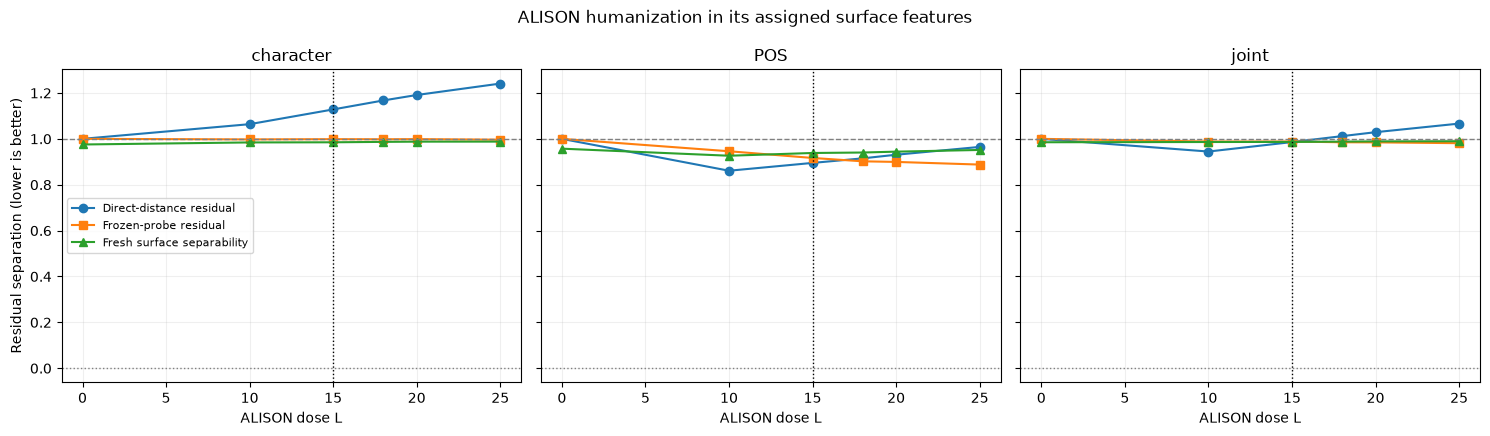

saved: ../results/causal/C02c_alison_dose_calibration/alison_surface_feature_humanization.png

Primary rule: decide surface humanization from H vs AL(A), not from AL(H) or OpenAI-detector probabilities.


In [18]:
columns = [
    "feature_family", "dose",
    "fraction_coordinates_closer",
    "fraction_coordinates_overshot",
    "centroid_l2_fraction_erased",
    "energy_distance_fraction_erased",
    "rbf_mmd_fraction_erased",
    "coordinate_l1_gap_fraction_erased",
    "major256_l1_gap_fraction_erased",
    "frozen_probe_auc",
    "frozen_probe_residual_ratio",
    "fresh_surface_probe_auc",
    "fresh_surface_probe_auc_ci_low",
    "fresh_surface_probe_auc_ci_high",
    "fresh_auc_equivalent_within_0.05",
    "all_direct_distances_improved",
]

print("ALL DOSES: H vs AL(A), ALISON FEATURES ONLY")
display(
    surface_summary[columns]
    .sort_values(["feature_family", "dose"])
    .round(4)
)

print("PRESELECTED L=15")
display(
    surface_summary[surface_summary.dose.eq(15)][columns]
    .round(4)
)

print("EXPLORATORY JOINT-SPACE RANKING")
display(
    surface_summary[
        surface_summary.feature_family.eq("joint")
        & surface_summary.dose.gt(0)
    ][[
        "dose",
        "mean_direct_residual_ratio",
        "frozen_probe_residual_ratio",
        "fresh_surface_probe_auc",
        "fresh_surface_probe_auc_ci_low",
        "fresh_surface_probe_auc_ci_high",
        "fresh_auc_equivalent_within_0.05",
    ]]
    .sort_values(["mean_direct_residual_ratio", "dose"])
    .round(4)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)

for ax, family in zip(axes, ["character", "POS", "joint"]):
    d = surface_summary[
        surface_summary.feature_family.eq(family)
    ].sort_values("dose")
    ax.plot(
        d.dose, d.mean_direct_residual_ratio,
        marker="o", label="Direct-distance residual",
    )
    ax.plot(
        d.dose, d.frozen_probe_residual_ratio,
        marker="s", label="Frozen-probe residual",
    )
    ax.plot(
        d.dose, 2 * (d.fresh_surface_probe_auc - 0.5).abs(),
        marker="^", label="Fresh surface separability",
    )
    ax.axhline(1, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.axvline(15, color="black", linestyle=":", linewidth=1)
    ax.set_title(family)
    ax.set_xlabel("ALISON dose L")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Residual separation (lower is better)")
axes[0].legend(fontsize=8)
fig.suptitle("ALISON humanization in its assigned surface features")
fig.tight_layout()

SURFACE_FIG = OUT / "alison_surface_feature_humanization.png"
fig.savefig(SURFACE_FIG, dpi=180, bbox_inches="tight")
plt.show()

print("saved:", SURFACE_FIG)
print(
    "\nPrimary rule: decide surface humanization from H vs AL(A), "
    "not from AL(H) or OpenAI-detector probabilities."
)